# Analysis - Perceptual load / working memory manipulation

Final GLM analysis on alignment-adjusted data.

## Used montage

![montage](img/montage.png)

# Set parameters and read data

In [1]:
import os

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd
import glob

import seaborn as sns
import statsmodels.formula.api as smf
import matplotlib as mpl

from itertools import compress
from nilearn.plotting import plot_design_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests

# BIDS dataset and task
task = "lettersearch"
bids_root = "data/lettersearch_BIDS"
datatype = 'nirs'
bids_folder = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files = bids_folder.match()

# Prepare folder for processed data
glm_folder = "data/glm_data"
if not os.path.isdir(glm_folder):
    os.mkdir(glm_folder)

# Parameters used
sci_limit = 0.8
excluded_participants = []

# For visualization
subjects_dir = str(mne.datasets.sample.data_path()) + '/subjects'
mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir)
mne.set_config('MNE_NIRS_FOLD_PATH', 'data/fOLD-public/Supplementary')

# Offsets
offsets_path = "data/trigger_offsets.csv"
if os.path.exists(offsets_path):
    trigger_offsets = pd.read_csv(offsets_path).set_index('subject')['lag_sec']
    print(f"Loaded trigger offsets for {len(trigger_offsets)} subjects:")
    print(trigger_offsets.to_string())
else:
    trigger_offsets = pd.Series(dtype=float)
    print(f"WARNING: {offsets_path} not found — no ACC offsets applied")

0 files missing from root.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects
0 files missing from bem.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects/fsaverage
Loaded trigger offsets for 16 subjects:
subject
P1      0.0
P10    13.0
P11     5.0
P12     0.0
P13     0.0
P14     2.0
P15     3.0
P17     0.0
P2      0.0
P3      0.0
P4      0.0
P5      8.0
P6     -7.0
P7     45.0
P8      0.0
P9     -5.0


# Set up design matrix

The design matrix includes practice and experimental condtions, a constant + cosine drift regressors, short channel regressors, a nuisance regressor for the pause in the protocol, and finally [TCCA](https://doi.org/10.1016/j.neuroimage.2019.116472) regressors built from accelerometer and gyroscope data in auxilliary channels.

Drift regressor cutoff is based on the ISI in the experiment, according to MNE-NIRS and Nilearn documentation:

> the cutoff period (1/high_pass) should be set as the longest period between two trials of the same condition multiplied by 2.

- <https://mne.tools/mne-nirs/stable/auto_examples/general/plot_14_glm_components.html#drift-regressors>
- <https://nilearn.github.io/dev/auto_examples/04_glm_first_level/plot_first_level_details.html> 

In this case, the longest ISI was determined to be 16.9 seconds. This can be computed via the function [_longest_inter_annotation_interval_](https://mne.tools/mne-nirs/stable/generated/mne_nirs.experimental_design.longest_inter_annotation_interval.html). This means that the high_pass value should be 1 / (2*16.9) = 1 / 33.8 ≈ 0.0295

Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
          ACCEL_X_1  ACCEL_X_2  ACCEL_Y_2  ACCEL_Z_2  GYRO_X_2  GYRO_Y_2  \
times                                                                      
0.000000  -0.025000  -0.004000   1.060000  -9.197000 -0.015251  0.000000   
0.196608  -0.058828  -0.078241   1.150174  -9.190414  0.052679 -0.045756   
0.393216   0.028000  -0.210378   1.011860  -9.194551 -0.007595 -0.008514   
0.589824  -0.028556  -0.117207   1.053747  -9.219788 -0.047704 -0.00099

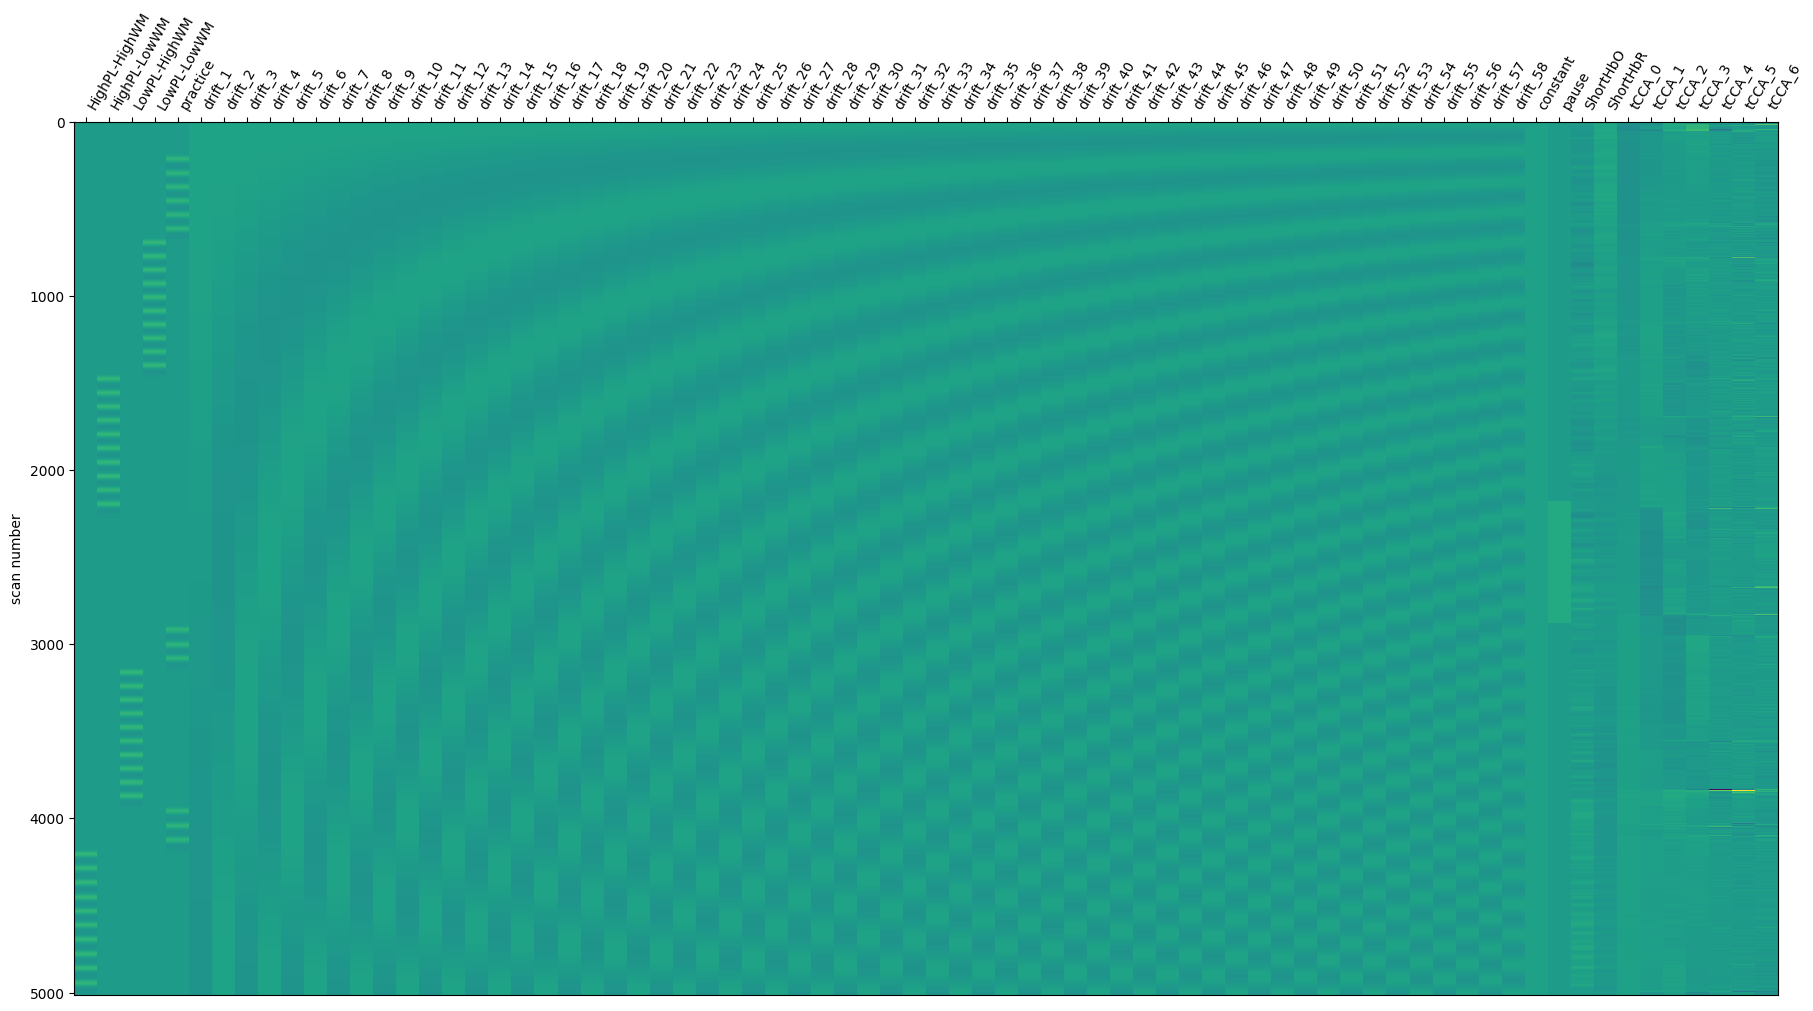

In [2]:
# Get all subjects in a sorted list
all_subjects = [file.subject for file in nirs_files]
all_subjects = sorted(list(set(all_subjects)))

# Get hemo data for one subject to illustrate design matrix
subject = all_subjects[0]
bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)

raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

# Split into long/short
long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

# Convert to hemoglobin
raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)
raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

# Create a design matrix
design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                            drift_model="cosine",
                                                                            stim_dur=5,
                                                                            hrf_model="glover",
                                                                            high_pass=0.0295)

# Add a boxcar regressor for the long pause
# First get gaps between blocks
onsets = raw_haemo_long.annotations.onset
durations = raw_haemo_long.annotations.duration
ends = onsets + durations
gaps = onsets[1:] - ends[:-1]

# The longest gap is guaranteed to be the pause
pause_idx = np.argmax(gaps)
pause_start_sec = ends[pause_idx]
pause_stop_sec = onsets[pause_idx+1]

# Create a pause regressor (can be confirmed visually)
pause_regressor = np.zeros(len(raw_haemo_long.times))
start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
pause_regressor[start_idx:stop_idx] = 1.0
design_matrix["pause"] = pause_regressor

# Add short separation regressors
design_matrix["ShortHbO"] = np.mean(
    raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
)
design_matrix["ShortHbR"] = np.mean(
    raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
)

# Add acceleration regressors
aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
print(aux_df.head())

aux_all = aux_df.to_numpy()
nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T

reg, tcca_info = mne_nirs.experimental_design.rtcca(
    nirs_data,
    aux_all,
    tau=1,
    n_emb=3,
    ct=0.3,
    pca_fnirs = False,
    pca_aux = False,
    shrink=True
)

print(reg.shape)
reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
for i, name in zip(range(reg.shape[1]), reg_names):
    design_matrix[name] = reg[:, i]

# Plot final matrix
ax = plot_design_matrix(design_matrix)

ax.figure.savefig(
    "img/design_matrix.svg",
    bbox_inches="tight"
)

plt.show()

In [3]:
# Go through data for each subject
cha_frames = []
for subject in all_subjects:
    
    # Get SNIRF file for this subject
    bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)
    
    print(f"Processing {bids_path}..")
    if not os.path.exists(bids_path):
        print(f"No SNIRF file, skip: {bids_path}")
        continue

    # Raw data
    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

    # Apply per-subject trigger offset from alignment_notebook
    if subject in trigger_offsets.index:
        _off = float(trigger_offsets[subject])
        _ann = raw_intensity.annotations
        raw_intensity.set_annotations(mne.Annotations(
            onset       = _ann.onset + _off,
            duration    = _ann.duration,
            description = _ann.description,
        ))
        print(f"  trigger offset applied: {_off:+.3f} s")
    else:
        print(f"  no offset for {subject} — using as-is")

    # Split into long/short
    long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
    short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

    # Convert to OD
    raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
    raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)

    # Channel quality
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od_long)
    bad_channels = list(compress(raw_od_long.ch_names, sci < sci_limit))
    
    # Get bad channel names as e.g. S1_D1 instead of S1_D1 760 and S1_D1 850
    bad_channels = np.unique([channel.replace(" 760", "").replace(" 850", "") for channel in np.unique(bad_channels)]).tolist()
    print(f"Bad channels with SCI < {sci_limit}:")
    print(bad_channels)

    # Use the MBLL to convert into hemoglobin changes
    raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
    raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

    # Where to store results from the GLM analysis
    glm_fname = f"{glm_folder}/{subject}_glm.h5"

    # Create a design matrix
    design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                                stim_dur=5,
                                                                                drift_model="cosine",
                                                                                hrf_model="glover",
                                                                                high_pass=0.0295)
    design_matrix["ShortHbO"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
    )
    design_matrix["ShortHbR"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
    )

    # Add a boxcar regressor for the long pause
    # First get gaps between blocks
    onsets = raw_haemo_long.annotations.onset
    durations = raw_haemo_long.annotations.duration
    ends = onsets + durations
    gaps = onsets[1:] - ends[:-1]
    
    # The longest gap is guaranteed to be the pause
    pause_idx = np.argmax(gaps)
    pause_start_sec = ends[pause_idx]
    pause_stop_sec = onsets[pause_idx+1]
    
    # Create a pause regressor (can be confirmed visually)
    pause_regressor = np.zeros(len(raw_haemo_long.times))
    start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
    stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
    pause_regressor[start_idx:stop_idx] = 1.0
    design_matrix["pause"] = pause_regressor

    # Add acceleration regressors via TCCA
    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
    aux_all = aux_df.to_numpy()
    nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T
    reg, tcca_info = mne_nirs.experimental_design.rtcca(
        nirs_data,
        aux_all,
        tau=1,
        n_emb=3,
        ct=0.3,
        pca_fnirs = False,
        pca_aux = True,
        shrink=True
    )
    reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
    for i, name in zip(range(reg.shape[1]), reg_names):
        design_matrix[name] = reg[:, i]

    # Save per-subject VIF
    vif_vals = {design_matrix.columns[i]: variance_inflation_factor(design_matrix.values, i)
                for i in range(design_matrix.shape[1])}
    pd.Series(vif_vals).to_csv(f"{glm_folder}/{subject}_vif.csv")

    # Run GLM and save
    glm_est = mne_nirs.statistics.run_glm(raw_haemo_long, design_matrix, noise_model="auto")
    glm_est.save(glm_fname, overwrite=True)

    # If we want to visualize subject-level GLM
    #glm_est.plot_topo(conditions=['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'])
    #plt.show()

    # Append results per channel to larger dataframe for later export
    cha = glm_est.to_dataframe()

    # Add 'channel_ok' column as True for good channels, False for bad channels
    cha['channel_ok'] = cha['ch_name'].apply(lambda x: x.split(' ')[0] not in bad_channels)

    # Append to final dataframes
    cha['subject'] = subject
    cha_frames.append(cha)

cha_data = pd.concat(cha_frames, ignore_index=True)
cha_data.to_csv("data/cha_data.csv")

print('done')

# Also save a raw object for later plotting purposes
raw_haemo_long.save("data/raw.fif", overwrite=True)

Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
  trigger offset applied: +0.000 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Bad channels with SCI < 0.8:
[]
Processing data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearc

[PosixPath('/Users/alexander.kvist/project_local/Perceptual-fnirs/data/raw.fif')]

# Variance inflation factors - are the condition regressors orthogonal?

Variance inflation factors (VIFs) can tell us if our design matrix has problematic collinearity. VIF < 5 for task regressors indicates acceptable orthogonality to other regressors. Note that high VIF for nuisance regressors (drift, tCCA) is acceptable, because we only need them to absorb noise, not to be estimated precisely.

VIF limits in neuroimaging GLM regressors:
- O'Brien 2007 <https://doi.org/10.1007/s11135-006-9018-6>
- Mumford 2015 <https://doi.org/10.1371/journal.pone.0126255>


In [4]:
# Load per-subject VIFs saved during the main processing loop and report the mean.
vif_files = sorted(glob.glob(f"{glm_folder}/*_vif.csv"))
vif_rows = {}
for f in vif_files:
    subject_name = os.path.basename(f).replace("_vif.csv", "")
    series = pd.read_csv(f, index_col=0, header=None).squeeze()
    vif_rows[subject_name] = series

vif_df = pd.DataFrame(vif_rows).T

print(f"Mean VIF across {len(vif_files)} subjects:\n")
print(vif_df.mean().to_string())


Mean VIF across 16 subjects:

0
HighPL-HighWM      1.282366
HighPL-LowWM       1.325663
LowPL-HighWM       1.289286
LowPL-LowWM        1.285847
ShortHbO          24.808516
ShortHbR          83.520246
constant           8.210033
drift_1          106.092513
drift_10           3.527098
drift_11           1.891240
drift_12           2.319596
drift_13           1.708528
drift_14           1.489947
drift_15           1.639953
drift_16           1.644657
drift_17           1.639032
drift_18           1.708285
drift_19           1.664641
drift_2           25.192558
drift_20           1.691444
drift_21           1.653831
drift_22           1.630143
drift_23           1.478254
drift_24           1.388609
drift_25           1.358248
drift_26           1.313531
drift_27           1.234842
drift_28           1.189096
drift_29           1.238722
drift_3           13.920894
drift_30           1.220544
drift_31           1.209312
drift_32           1.226050
drift_33           1.224497
drift_34        

# Group level analysis - channel-level

Channel-level results from the subject-level GLM analyses are analyzed in a linear mixed effects model.

The model is specified as:

$$theta \sim -1 + ch\_name:Chroma:Condition$$

Channel-level results are corrected with Benjamini-Hochberg FDR correction, to control for multiple comparisons across channels.

In [5]:
cha_data = pd.read_csv("data/cha_data.csv", index_col=0)
raw_haemo_long = mne.io.read_raw_fif("data/raw.fif")

# Get data from the channel level frame - exclude channels flagged as bad during preprocessing
ch_summary_hbo = cha_data.query(
    "Condition in ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'] and channel_ok == True"
)
ch_summary_hbo["theta"] = [t * 1.e6 for t in ch_summary_hbo["theta"]]
ch_summary_hbo = ch_summary_hbo.query("Chroma in ['hbo']")

# Run group level model and convert to dataframe
ch_model_hbo = smf.mixedlm("theta ~ -1 + ch_name:Chroma:Condition",
                    ch_summary_hbo, groups=ch_summary_hbo["subject"]).fit()
ch_model_df_hbo = mne_nirs.statistics.statsmodels_to_results(ch_model_hbo, order=raw_haemo_long.copy().pick("hbo").ch_names)

# FDR correction (Benjamini-Hochberg) across all channel x condition tests
pvals_hbo = ch_model_df_hbo["P>|z|"].values
reject_hbo, pvals_fdr_hbo, _, _ = multipletests(pvals_hbo, alpha=0.05, method='fdr_bh')
ch_model_df_hbo["Significant"] = reject_hbo
ch_model_df_hbo["P_FDR"] = pvals_fdr_hbo
print(f"HbO: {reject_hbo.sum()} FDR-significant out of {len(reject_hbo)} tests")

# Save the stat output
ch_model_df_hbo.to_csv("data/cha_model_df_hbo.csv")

# Display results
ch_model_df_clean = ch_model_df_hbo.copy()
ch_model_df_clean.reset_index(drop=True, inplace=True)
ch_model_df_clean = ch_model_df_clean.set_index(["ch_name", "Condition"])
print(ch_model_df_clean[ch_model_df_clean["Significant"] == True])

# Again for HbR - exclude bad channels
ch_summary_hbr = cha_data.query(
    "Condition in ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'] and channel_ok == True"
)
ch_summary_hbr["theta"] = [t * 1.e6 for t in ch_summary_hbr["theta"]]
ch_summary_hbr = ch_summary_hbr.query("Chroma in ['hbr']")

ch_model_hbr = smf.mixedlm("theta ~ -1 + ch_name:Chroma:Condition",
                    ch_summary_hbr, groups=ch_summary_hbr["subject"]).fit()
ch_model_df_hbr = mne_nirs.statistics.statsmodels_to_results(ch_model_hbr, order=raw_haemo_long.copy().pick("hbr").ch_names)

# FDR correction
pvals_hbr = ch_model_df_hbr["P>|z|"].values
reject_hbr, pvals_fdr_hbr, _, _ = multipletests(pvals_hbr, alpha=0.05, method='fdr_bh')
ch_model_df_hbr["Significant"] = reject_hbr
ch_model_df_hbr["P_FDR"] = pvals_fdr_hbr
ch_model_df_hbr.to_csv("data/cha_model_df_hbr.csv")
print(f"HbR: {reject_hbr.sum()} FDR-significant out of {len(reject_hbr)} tests")

# Display results
ch_model_df_clean = ch_model_df_hbr.copy()
ch_model_df_clean.reset_index(drop=True, inplace=True)
ch_model_df_clean = ch_model_df_clean.set_index(["ch_name", "Condition"])
print(ch_model_df_clean[ch_model_df_clean["Significant"] == True])



Opening raw data file data/raw.fif...
    Range : 0 ... 4897 =      0.000 ...   962.789 secs
Ready.
HbO: 3 FDR-significant out of 176 tests
                              Coef.  Std.Err.         z     P>|z|    [0.025  \
ch_name     Condition                                                         
S2_D3 hbo   HighPL-HighWM  4.153931  0.976024  4.255973  0.000021  2.240960   
            LowPL-HighWM   3.684226  0.976024  3.774730  0.000160  1.771255   
S11_D11 hbo HighPL-HighWM -3.354537  1.005192 -3.337210  0.000846 -5.324678   

                             0.975] Chroma  Significant     P_FDR  
ch_name     Condition                                              
S2_D3 hbo   HighPL-HighWM  6.066903    hbo         True  0.003663  
            LowPL-HighWM   5.597198    hbo         True  0.014096  
S11_D11 hbo HighPL-HighWM -1.384397    hbo         True  0.049646  
HbR: 1 FDR-significant out of 176 tests
                              Coef.  Std.Err.         z     P>|z|    [0.025  \
ch_na

# Group level topoplot

HbO


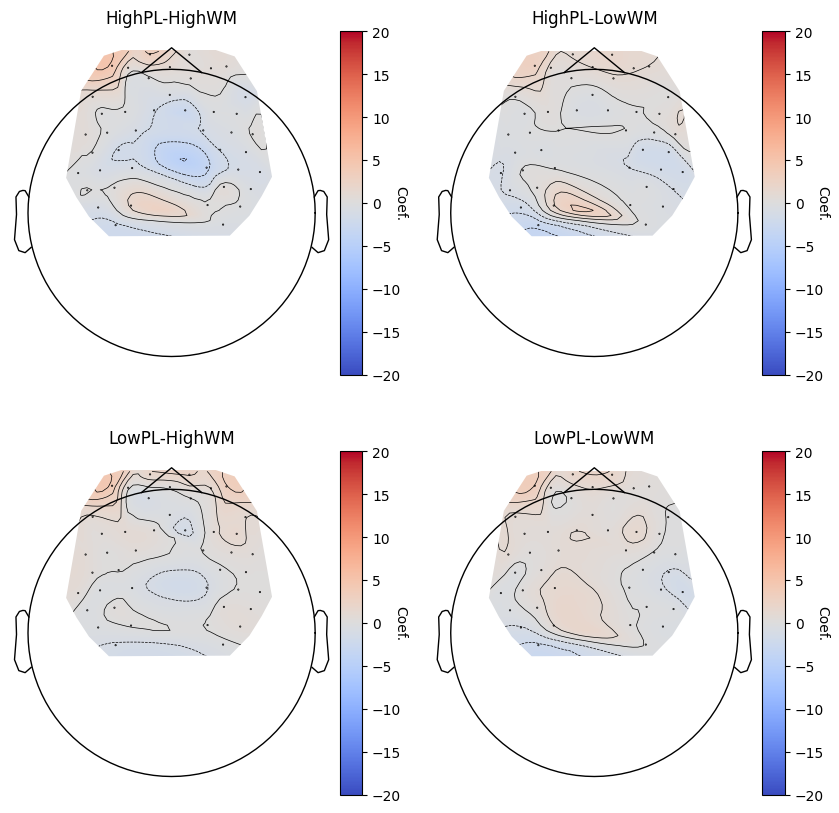

HbR


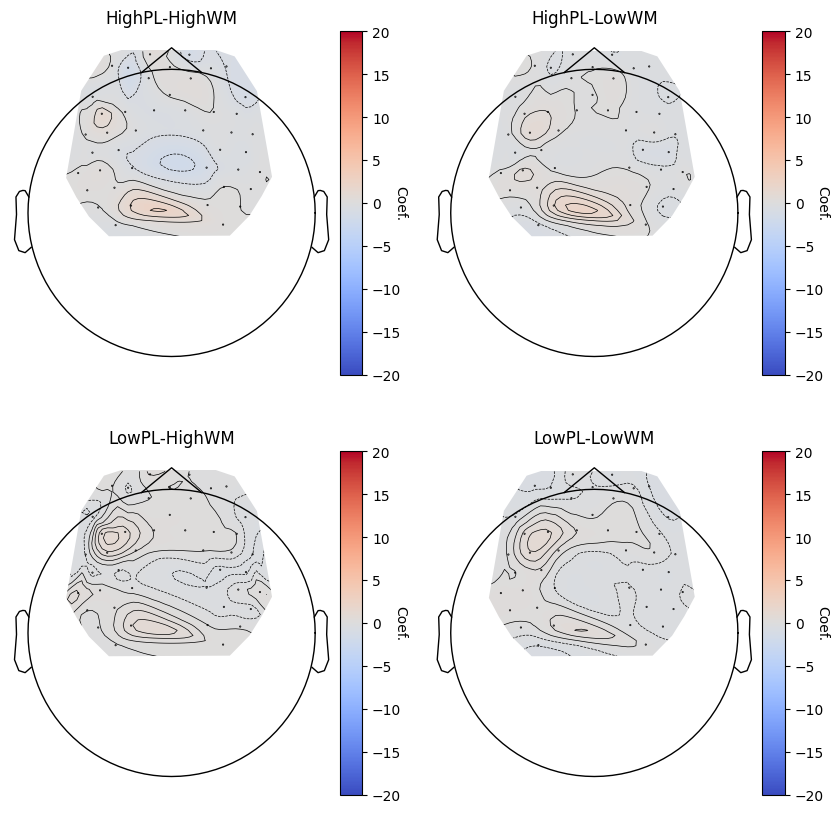

In [6]:
# Plot 2D 
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]

print("HbO")
idx = 0
for cond in conditions:
    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    mne_nirs.visualisation.plot_glm_group_topo(raw_haemo_long.copy().pick(picks="hbo"),
                        ch_model_df_hbo.query(f"Condition in ['{cond}']"),
                        colorbar=True, axes=axes[cur_row, cur_col],
                        vlim=(-20, 20), cmap=mpl.cm.coolwarm, threshold=False)
    idx += 1
plt.show()

print("HbR")
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]

idx = 0
for cond in conditions:
    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    mne_nirs.visualisation.plot_glm_group_topo(raw_haemo_long.copy().pick(picks="hbr"),
                        ch_model_df_hbr.query(f"Condition in ['{cond}']"),
                        colorbar=True, axes=axes[cur_row, cur_col],
                        vlim=(-20, 20), cmap=mpl.cm.coolwarm, threshold=False)
    idx += 1
plt.show()




# Group level topoplot - only significant

HbO


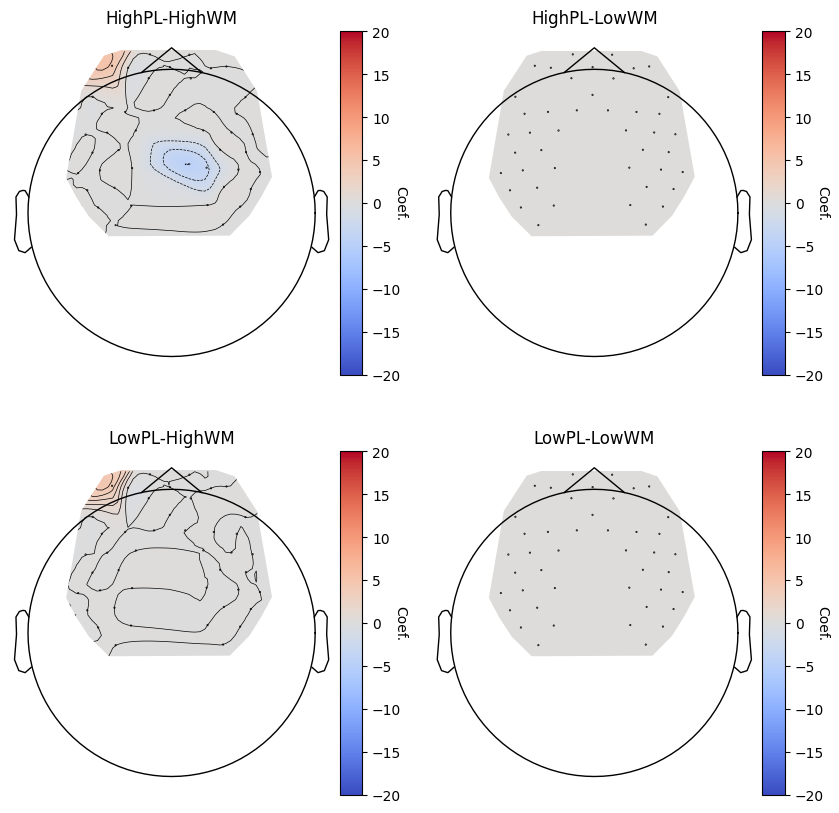

HbR


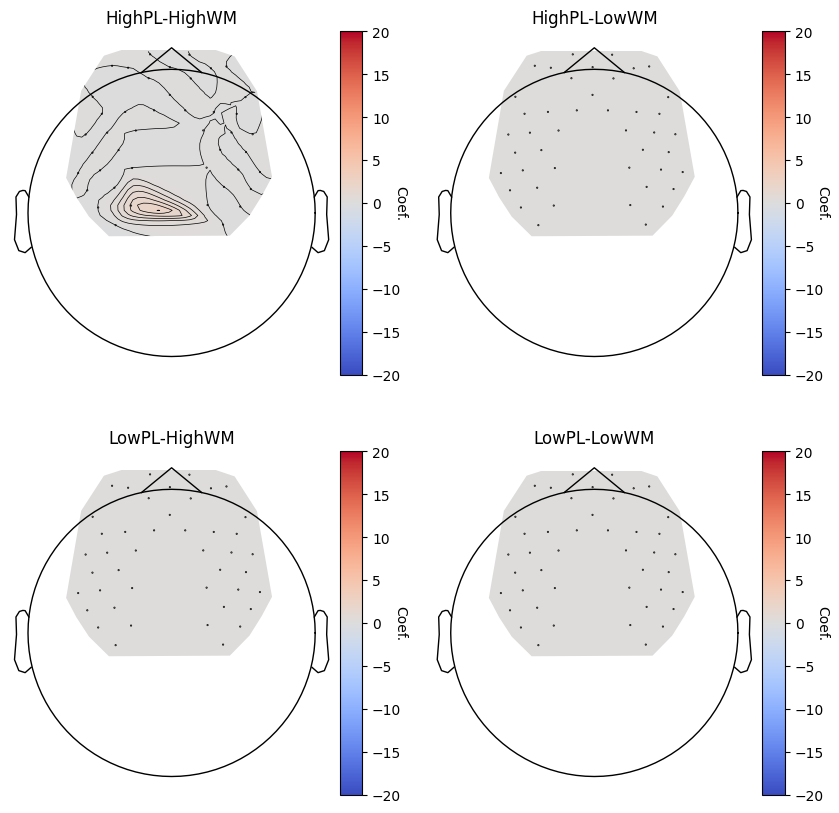

In [7]:
print("HbO")
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]
idx = 0
for cond in conditions:

    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    
    stats_cond = (
        ch_model_df_hbo
        .query(f"Condition == '{cond}'")
        .copy()
    )
    
    # Manually zero non‑significant estimates
    stats_cond.loc[~stats_cond["Significant"], "Coef."] = 0.0
    
    mne_nirs.visualisation.plot_glm_group_topo(
        raw_haemo_long.copy().pick(picks="hbo"),
        stats_cond,
        colorbar=True,
        axes=axes[cur_row, cur_col],
        vlim=(-20, 20),
        cmap=mpl.cm.coolwarm,
        threshold=False,
    )

    idx += 1
plt.show()

print("HbR")
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]
idx = 0
for cond in conditions:

    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    
    stats_cond = (
        ch_model_df_hbr
        .query(f"Condition == '{cond}'")
        .copy()
    )
    
    # Manually zero non‑significant estimates
    stats_cond.loc[~stats_cond["Significant"], "Coef."] = 0.0
    
    mne_nirs.visualisation.plot_glm_group_topo(
        raw_haemo_long.copy().pick(picks="hbr"),
        stats_cond,
        colorbar=True,
        axes=axes[cur_row, cur_col],
        vlim=(-20, 20),
        cmap=mpl.cm.coolwarm,
        threshold=False,
    )

    idx += 1
plt.show()



# Group level analysis - Contrasts

Opening raw data file data/raw.fif...
    Range : 0 ... 4897 =      0.000 ...   962.789 secs
Ready.
0 FDR-significant channel × contrast tests out of 132 for hbo
(none)
0 FDR-significant channel × contrast tests out of 132 for hbr
(none)


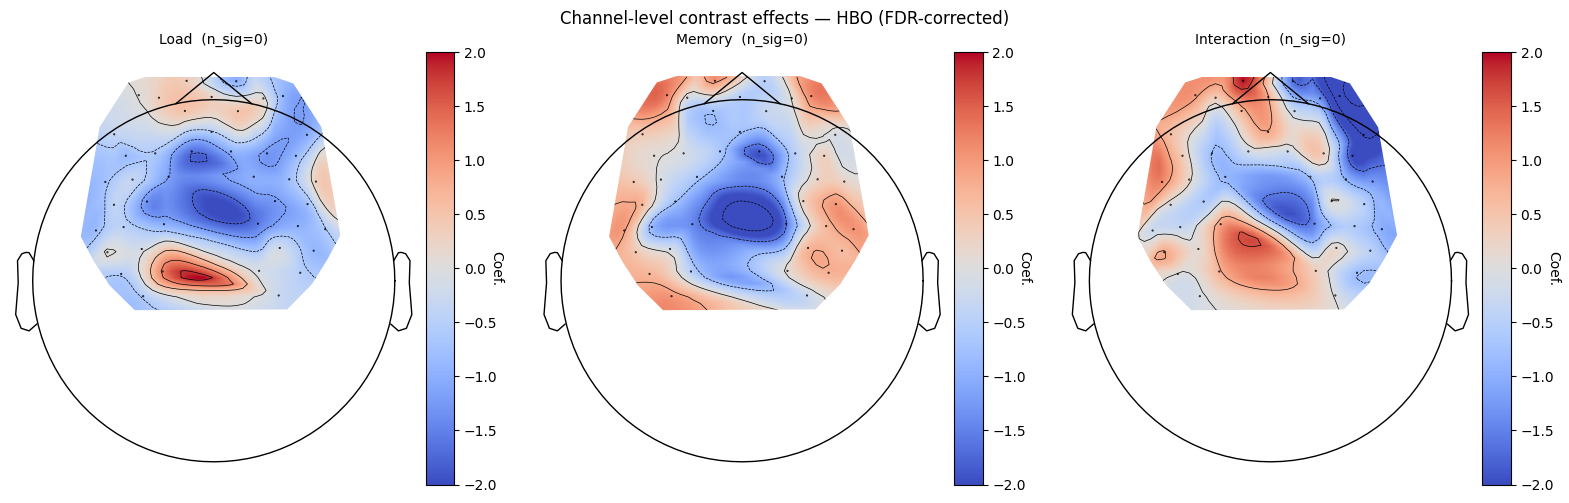

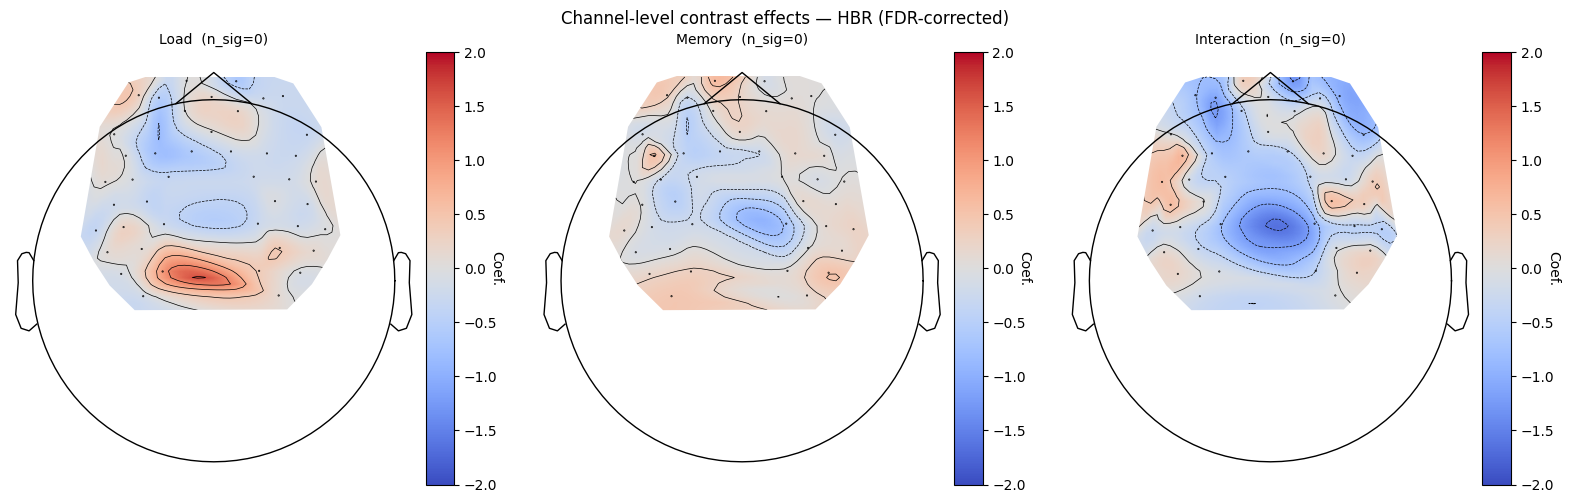

In [8]:
CONDITIONS = [
    "HighPL-HighWM",
    "HighPL-LowWM",
    "LowPL-HighWM",
    "LowPL-LowWM",
]

# Names for centered terms
TERMS = {
    "Load": "Load_c",
    "Memory": "Memory_c",
    "Interaction": "Load_c:Memory_c",
}

cha_data = pd.read_csv("data/cha_data.csv", index_col=0)
raw_haemo_long = mne.io.read_raw_fif("data/raw.fif")

ch_contrast_records = []

# For each chromo, run a mixed effects model
# with a centered effect coding to get main effects
# and also interaction across the 2x2 factorial design
for chroma in ["hbo", "hbr"]:
    ch_data = cha_data.query(
        "Condition in @CONDITIONS and channel_ok == True and Chroma == @chroma"
    ).copy()

    ch_data["theta"] *= 1e6

    # Centered coding across the levels (+- 0.5)
    ch_data["Load_c"] = np.where(
        ch_data["Condition"].str.startswith("HighPL"), 0.5, -0.5
    )
    ch_data["Memory_c"] = np.where(
        ch_data["Condition"].str.endswith("HighWM"), 0.5, -0.5
    )

    ch_names = raw_haemo_long.copy().pick(chroma).ch_names

    for ch in ch_names:
        d = ch_data[ch_data["ch_name"] == ch]
        
        mdl = smf.mixedlm(
            "theta ~ Load_c * Memory_c", d, groups=d["subject"]
        ).fit(maxiter=2000, disp=False)
        
        ci = mdl.conf_int(alpha=0.05)

        for label, term in TERMS.items():
            if term in mdl.pvalues.index:
                ch_contrast_records.append({
                    "ch_name":   ch,
                    "Chroma":    chroma,
                    "Condition": label,
                    "Coef.":     mdl.params[term],
                    "Std.Err.":  mdl.bse[term],
                    "CI95_low":   ci.loc[term, 0],
                    "CI95_high":  ci.loc[term, 1],
                    "z":         mdl.tvalues[term],
                    "P>|z|":     mdl.pvalues[term],
                    "sigma_e":   np.sqrt(mdl.scale),  # residual SD, used to pick channels for simr
                })

ch_contrast_df = pd.DataFrame(ch_contrast_records)
ch_contrast_df["P_FDR"] = np.nan
ch_contrast_df["Significant"] = False

# FDR adjust across all channels and effects per chromo
for chroma in ch_contrast_df["Chroma"].unique():
    idx = ch_contrast_df["Chroma"] == chroma

    reject, pvals_fdr, _, _ = multipletests(
        ch_contrast_df.loc[idx, "P>|z|"],
        alpha=0.05,
        method="fdr_bh",
    )

    ch_contrast_df.loc[idx, "P_FDR"] = pvals_fdr
    ch_contrast_df.loc[idx, "Significant"] = reject

    print(f"{reject.sum()} FDR-significant channel × contrast tests out of {len(reject)} for {chroma}")
    if reject.any():
        print(ch_contrast_df[ch_contrast_df["Significant"]].to_string(index=False))
    else:
        print("(none)")

# Save dataframe
ch_contrast_df.to_csv("data/main_effects_interactions.csv")

# Consistent scale
vmax = 2.0
    
for chroma in ["hbo", "hbr"]:
    raw_pick = raw_haemo_long.copy().pick(chroma)
    df_chroma = ch_contrast_df[ch_contrast_df["Chroma"] == chroma]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f"Channel-level contrast effects — {chroma.upper()} (FDR-corrected)", fontsize=12)

    for ax, term_label in zip(axes, ["Load", "Memory", "Interaction"]):
        stats_cond = df_chroma[df_chroma["Condition"] == term_label].copy()

        mne_nirs.visualisation.plot_glm_group_topo(
            raw_pick,
            stats_cond,
            colorbar=True,
            axes=ax,
            vlim=(-vmax, vmax),
            cmap=mpl.cm.coolwarm,
            threshold=False,
        )
        n_sig = stats_cond["Significant"].sum()
        ax.set_title(f"{term_label}  (n_sig={n_sig})", fontsize=10)

    plt.tight_layout()
    plt.show()

In [9]:
for chroma, d in ch_contrast_df.groupby("Chroma"):
    coef = d["Coef."]

    print(
        f"{chroma}: coefficients ranged from "
        f"{coef.min():.3f} to {coef.max():.3f} "
        f"(median {coef.median():.3f}, "
        f"IQR {coef.quantile(0.25):.3f}-{coef.quantile(0.75):.3f})."
    )

display(ch_contrast_df)

hbo: coefficients ranged from -2.913 to 1.895 (median -0.247, IQR -0.801-0.317).
hbr: coefficients ranged from -1.224 to 1.030 (median -0.078, IQR -0.268-0.126).


,ch_name,Chroma,Condition,Coef.,Std.Err.,CI95_low,CI95_high,z,P>|z|,sigma_e,P_FDR,Significant
0,S1_D1 hbo,hbo,Load,-0.803891,0.350588,-1.491031,-0.116751,-2.292978,0.021849,1.402352,0.576821,False
1,S1_D1 hbo,hbo,Memory,0.049474,0.350588,-0.637666,0.736614,0.141118,0.887777,1.402352,0.953343,False
2,S1_D1 hbo,hbo,Interaction,0.312262,0.701176,-1.062018,1.686542,0.445340,0.656074,1.402352,0.917340,False
3,S1_D2 hbo,hbo,Load,-0.654419,0.335282,-1.311560,0.002722,-1.951844,0.050957,1.298543,0.611480,False
4,S1_D2 hbo,hbo,Memory,-0.114808,0.335282,-0.771949,0.542333,-0.342422,0.732034,1.298543,0.926694,False
...,...,...,...,...,...,...,...,...,...,...,...,...
259,S16_D13 hbr,hbr,Memory,-0.026612,0.195149,-0.409096,0.355872,-0.136369,0.891530,0.755807,0.985839,False
260,S16_D13 hbr,hbr,Interaction,0.568072,0.390297,-0.196896,1.333041,1.455486,0.145535,0.755807,0.834469,False
261,S16_D15 hbr,hbr,Load,-0.295729,0.208536,-0.704453,0.112995,-1.418117,0.156157,0.834146,0.834469,False
262,S16_D15 hbr,hbr,Memory,0.126039,0.208536,-0.282685,0.534763,0.604400,0.545578,0.834146,0.854654,False


# Factorial contrasts - estimates and confidence intervals

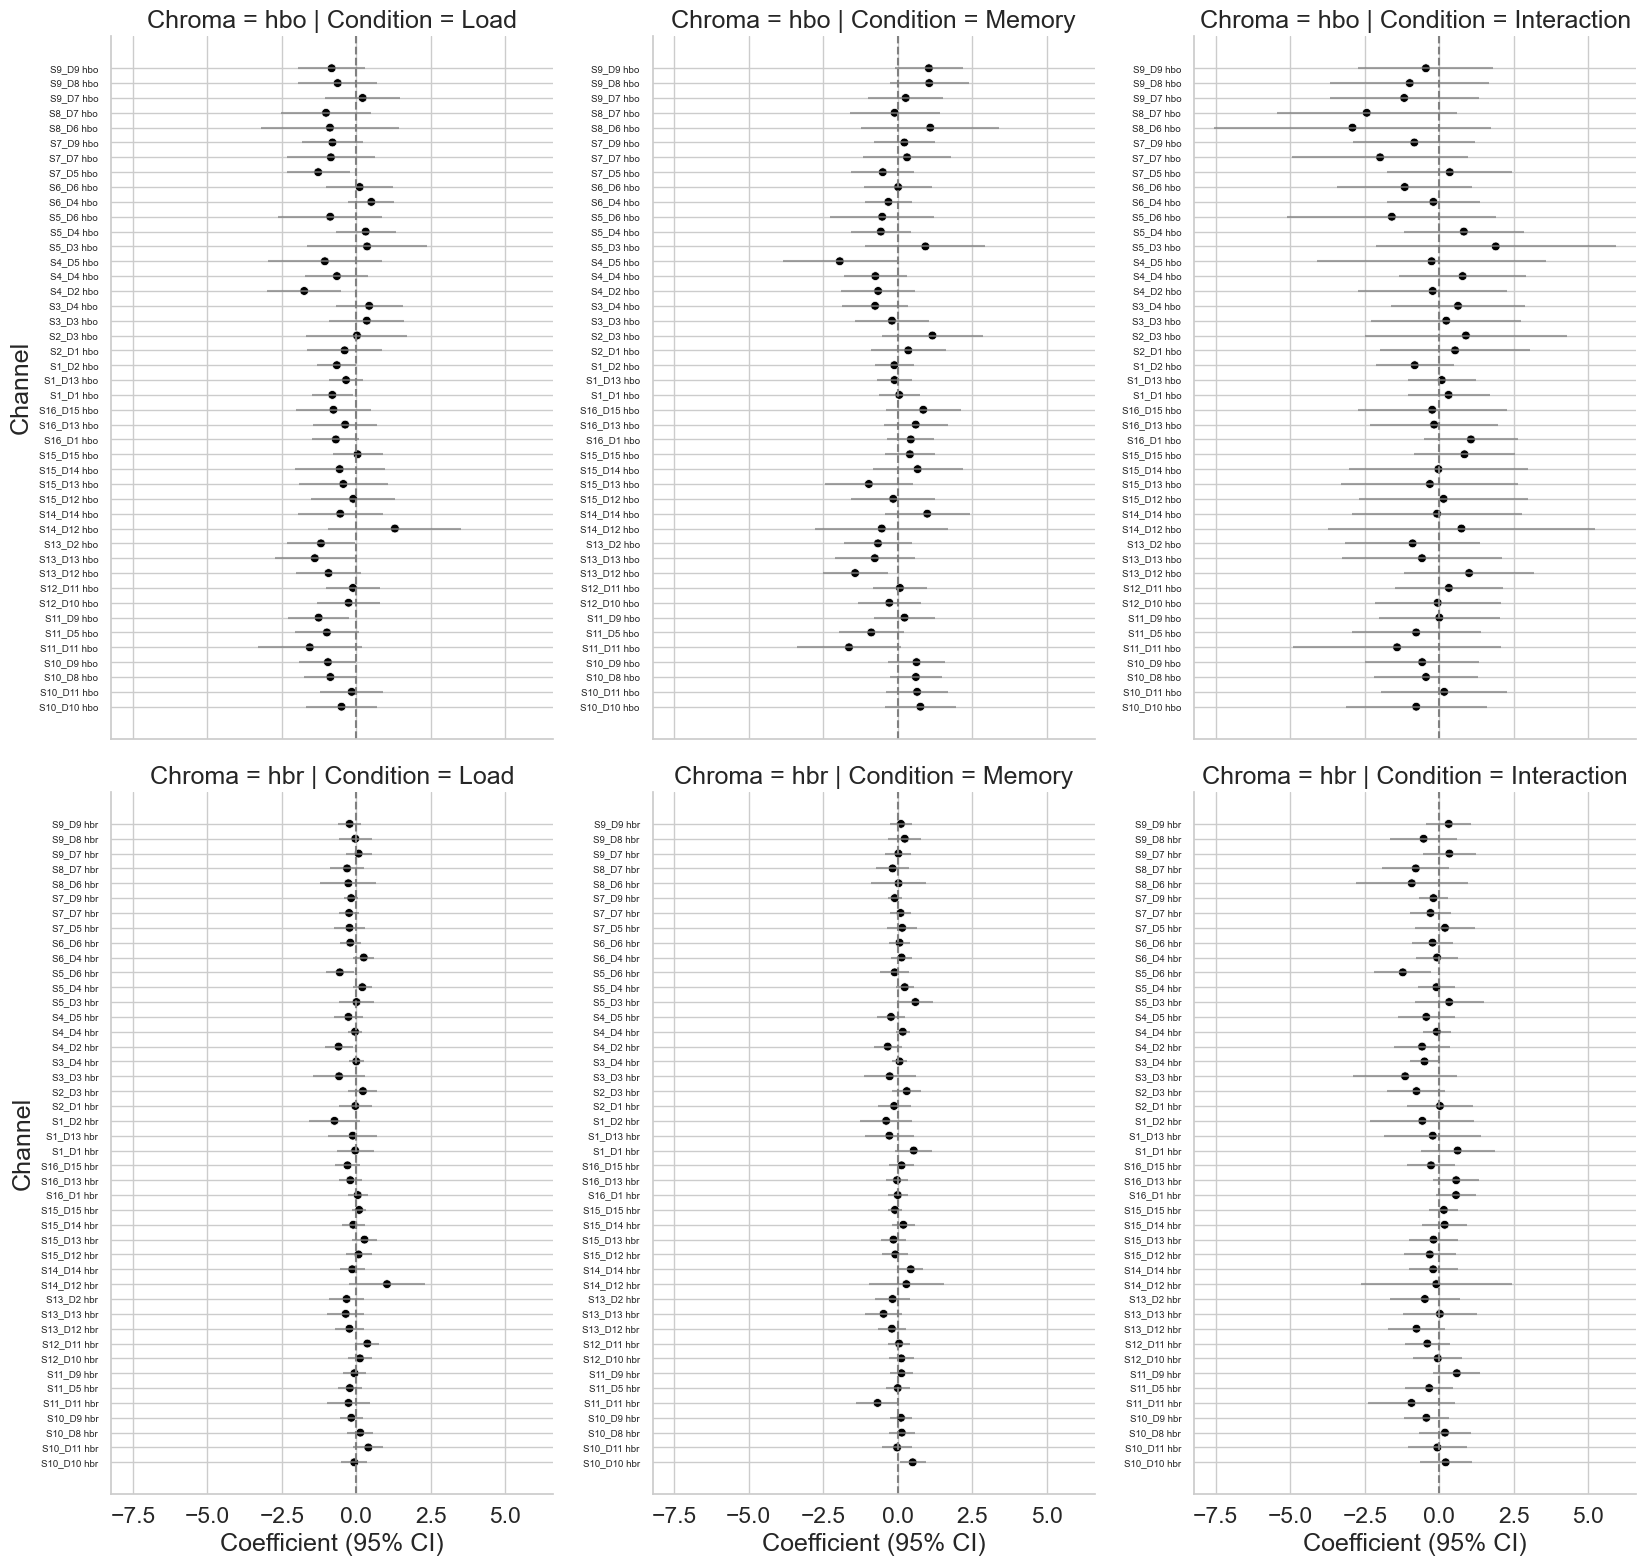

In [10]:
sns.set_theme(style="whitegrid", font_scale=1.5)

g = sns.FacetGrid(
    ch_contrast_df,
    row="Chroma",
    col="Condition",
    sharex=True,
    sharey=False,
    height=8,
    aspect=0.7,
)

def forestplot(data, color=None, **kwargs):
    ax = plt.gca()

    data = data.sort_values("ch_name")

    y = range(len(data))

    ax.hlines(
        y,
        data["CI95_low"],
        data["CI95_high"],
        color="0.5",
        alpha=0.7,
    )

    sns.scatterplot(
        data=data,
        x="Coef.",
        y=y,
        hue="Significant",
        palette={True: "red", False: "black"},
        legend=False,
        s=40,
        ax=ax,
    )

    ax.set_yticks(y)
    ax.set_yticklabels(data["ch_name"], fontsize=7)
    ax.axvline(0, ls="--", c="grey")

g.map_dataframe(forestplot)

g.set_axis_labels("Coefficient (95% CI)", "Channel")
plt.tight_layout()
plt.show()
g.figure.savefig(
    "img/coef_plot.svg",
    bbox_inches="tight"
)

# Sensitivity analysis - simulated power

Exports channel-level data for simulation-based power analysis in `mde_analysis.R` (simr).

In [11]:
simr_data = (
    cha_data
    .query("Condition in @CONDITIONS and channel_ok == True")
    .copy()
)

simr_data["theta"] *= 1e6

simr_data["Load_c"] = np.where(
    simr_data["Condition"].str.startswith("HighPL"), 0.5, -0.5
)

simr_data["Memory_c"] = np.where(
    simr_data["Condition"].str.endswith("HighWM"), 0.5, -0.5
)

simr_data[
    [
        "subject",
        "ch_name",
        "Chroma",
        "Condition",
        "Load_c",
        "Memory_c",
        "theta",
    ]
].to_csv(
    "data/simr_input.csv",
    index=False,
)

## Representative channels for simulation

What does minimum detectable effect for a given channel depend on? The channel's residual variability. Take the residual SD of each HbO channel's model. Select channels closest to the 10th percentile, median and 90th percentile of variability. These represent low, typical and high variability. Selection is written to `data/simr_channels.csv`.

In [12]:
# Residual SD per HbO channel, from the channel models in the contrast analysis
sigma_df = (
    ch_contrast_df.query("Chroma == 'hbo'")
    .drop_duplicates("ch_name")[["Chroma", "ch_name", "sigma_e"]]
    .reset_index(drop=True)
)

# Channel closest to the 10th percentile, median and 90th percentile of sigma_e
rep_records = []
for label, q in [("p10", 0.10), ("median", 0.50), ("p90", 0.90)]:
    target = sigma_df["sigma_e"].quantile(q)
    i = (sigma_df["sigma_e"] - target).abs().idxmin()
    row = sigma_df.loc[i].to_dict()
    row["Variability"] = label
    row["sigma_e_quantile"] = target
    rep_records.append(row)

rep_df = pd.DataFrame(rep_records)
rep_df.to_csv("data/simr_channels.csv", index=False)

display(rep_df.round(3))

,Chroma,ch_name,sigma_e,Variability,sigma_e_quantile
0,hbo,S16_D1 hbo,1.609,p10,1.641
1,hbo,S13_D2 hbo,2.238,median,2.260
2,hbo,S5_D6 hbo,3.577,p90,3.541
